# Matplotlib Exercises — Heart Disease Dataset

These exercises practise the matplotlib techniques from the **Introduction to Matplotlib** notebook, applied to the heart-disease dataset (303 patients).

You'll cover: plotting from a pandas DataFrame, scatter plots coloured by `target`, histograms, subplots (including a shared x-axis), the `over_50` analysis pattern, mean lines (`axhline`), colormaps (`cmap`), axis limits (`xlim`/`ylim`), and saving figures.

**The columns:**

| Column | Meaning |
|---|---|
| `age` | Age in years |
| `sex` | 0 = female, 1 = male |
| `cp` | Chest pain type (0–3) |
| `trestbps` | Resting blood pressure |
| `chol` | Serum cholesterol (mg/dl) |
| `thalach` | Maximum heart rate achieved |
| `target` | 1 = has heart disease, 0 = no heart disease |

**Instructions:** Solve each exercise in the empty cell below its prompt. Full answers are in the separate notebook **`matplotlib_exercises_solutions.ipynb`** — try each one yourself first.

## 0. Setup

**Exercise 0.** Import `matplotlib.pyplot` as `plt` and `pandas` as `pd`, enable inline plotting, and read `../data/heart-disease.csv` into a DataFrame called `heart_disease`. Show the first 5 rows.

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd


In [4]:
heart_disease = pd.read_csv('../matplotlib/heart-disease.csv')
heart_disease.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## 1. Plotting directly from a pandas DataFrame

**Exercise 1.** Plot a **histogram** of the `age` column directly from pandas using `.plot.hist()` with 50 bins. What does this tell you about the spread of ages?

<Axes: ylabel='Frequency'>

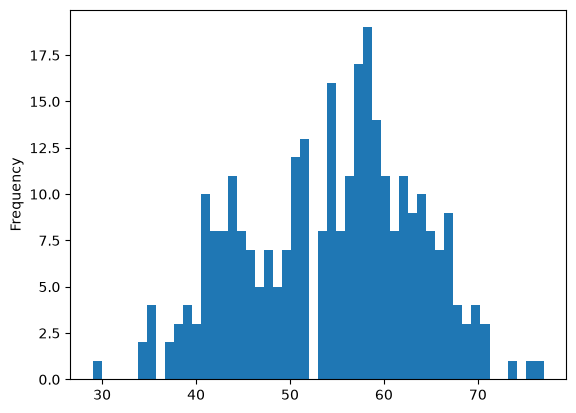

In [ ]:
heart_disease['age'].plot.hist(bins =50)
# the age ~60 has the most attacked by heart disease


**Exercise 2.** Plot a histogram of **every column at once** by calling `.plot.hist()` on the whole DataFrame with `subplots=True` and `figsize=(5, 20)`.

array([<Axes: ylabel='Frequency'>, <Axes: ylabel='Frequency'>,
       <Axes: ylabel='Frequency'>, <Axes: ylabel='Frequency'>,
       <Axes: ylabel='Frequency'>, <Axes: ylabel='Frequency'>,
       <Axes: ylabel='Frequency'>, <Axes: ylabel='Frequency'>,
       <Axes: ylabel='Frequency'>, <Axes: ylabel='Frequency'>,
       <Axes: ylabel='Frequency'>, <Axes: ylabel='Frequency'>,
       <Axes: ylabel='Frequency'>, <Axes: ylabel='Frequency'>],
      dtype=object)

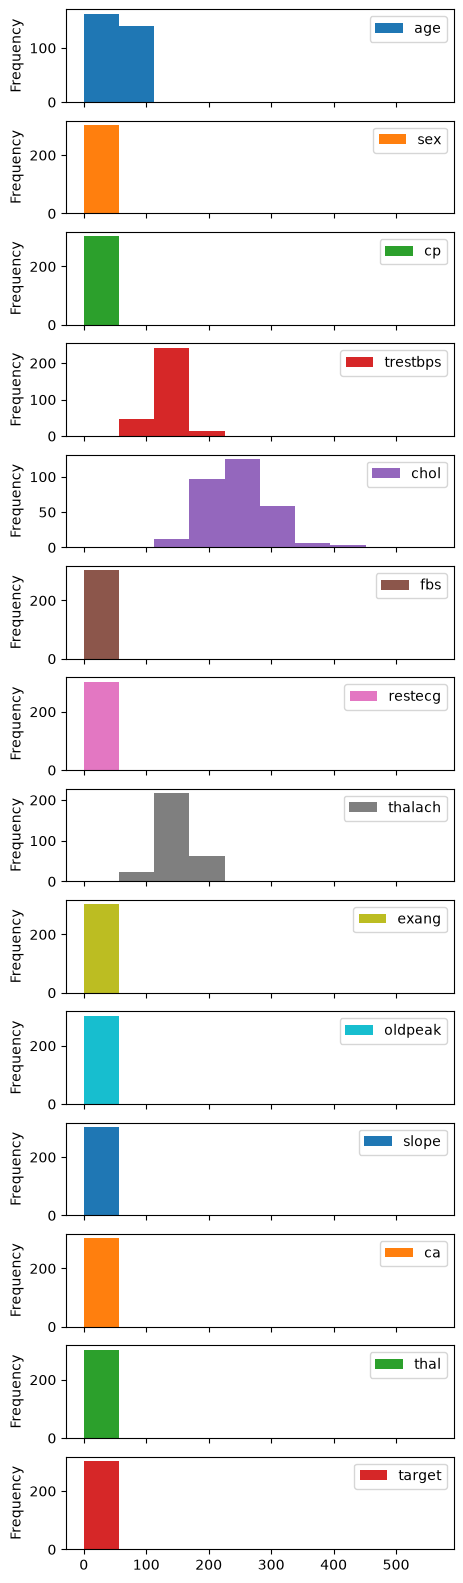

In [11]:
heart_disease.plot.hist(subplots = True, figsize = (5,20))


## 2. Analysing patients over 50

**Exercise 3.** Create a new DataFrame called `over_50` containing only the patients **older than 50** (`age > 50`). How many rows does it have?

In [34]:
over_50 = heart_disease[heart_disease['age'] > 50]
over_50


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,59,1,0,164,176,1,0,90,0,1.0,1,2,1,0
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [15]:
len(over_50)

208

**Exercise 4.** Using the object-oriented API (`fig, ax = plt.subplots(figsize=(10, 6))`), make a **scatter plot** of `over_50`'s `age` (x) vs `chol` (y), **colouring the points by the `target` column** (`c=over_50["target"]`).

Add a title "Heart Disease and Cholesterol Levels", axis labels, and a legend built with `ax.legend(*scatter.legend_elements(), title="Target")`.

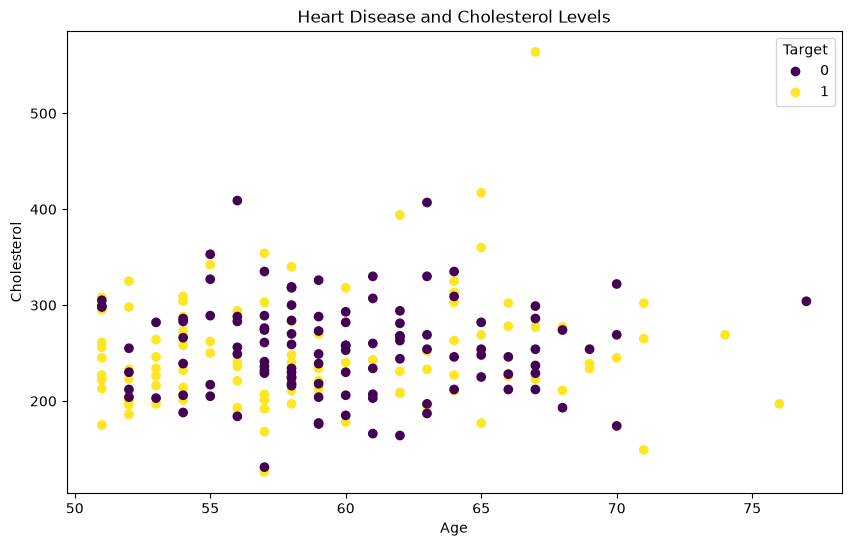

In [25]:
fig, ax = plt.subplots(figsize=(10, 6))

scatter = ax.scatter(over_50["age"], # x axis
                    over_50["chol"], # y axis
                    c=over_50["target"]) #controls the color of each point based on the target value.

plt.title("Heart Disease and Cholesterol Levels")
plt.xlabel("Age")
plt.ylabel("Cholesterol")  # or ax.set_xlabel , ax.set_title

ax.legend(
    *scatter.legend_elements(),
    title="Target"
)
# #automatically creates the legend information corresponding to the different colors.

# #The * unpacks the returned values so they can be passed to ax.legend().




**Exercise 5.** Recreate the scatter plot from Exercise 4, then add a **horizontal dashed line** showing the **mean cholesterol** using `ax.axhline(over_50["chol"].mean(), linestyle="--")`.

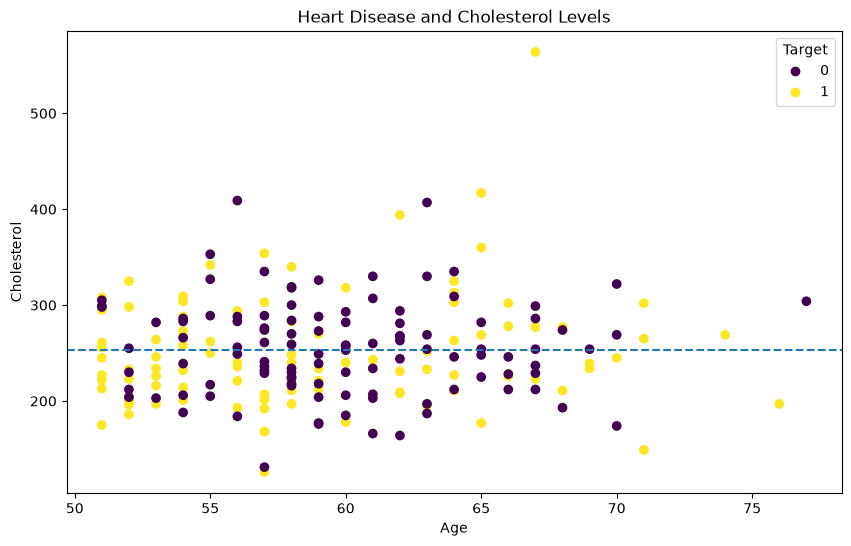

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

scatter = ax.scatter(over_50["age"], # x axis
                    over_50["chol"], # y axis
                    c=over_50["target"]) #controls the color of each point based on the target value.
plt.title("Heart Disease and Cholesterol Levels")
plt.xlabel("Age")
plt.ylabel("Cholesterol")  # or ax.set_xlabel , ax.set_title

ax.legend(
    *scatter.legend_elements(),
    title="Target"
)

ax.axhline(over_50["chol"].mean(), linestyle="--")


## 3. Multiple Axes on one Figure

**Exercise 6.** Create a Figure with **2 rows and 1 column** of Axes that **share the x-axis** (`nrows=2, ncols=1, sharex=True, figsize=(10, 8)`):

- top Axis (`ax0`): scatter of `over_50` `age` vs `chol`, coloured by `target`
- bottom Axis (`ax1`): scatter of `over_50` `age` vs `thalach`, coloured by `target`

Give each Axis a title and y-label, and a legend.

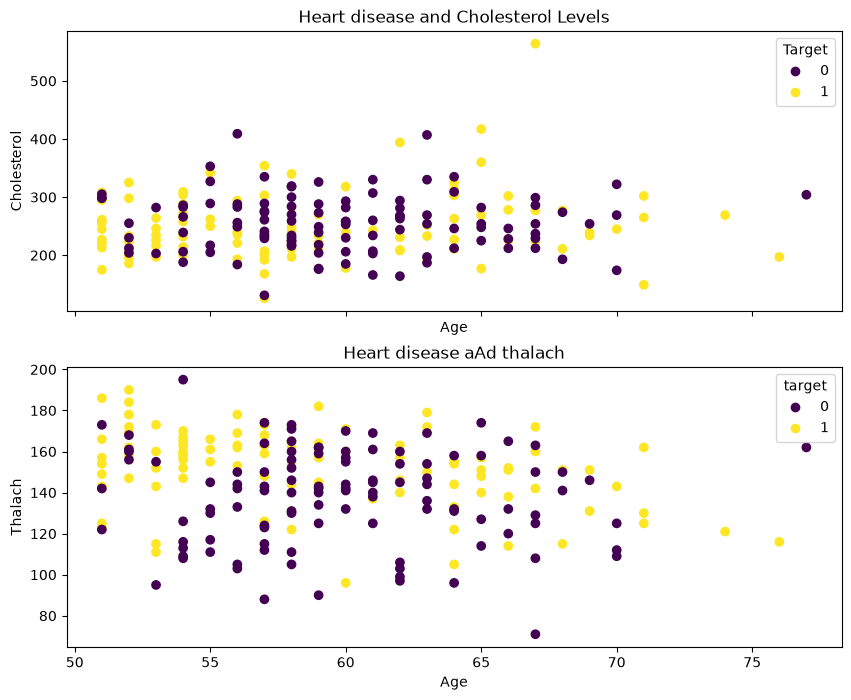

In [30]:
fig, (ax0,ax1) = plt.subplots(nrows=2, ncols=1, sharex=True, figsize=(10, 8))

ax0.scatter(over_50["age"], # x axis
                    over_50["chol"], # y axis
                    c=over_50["target"])

ax0.set_title("Heart disease and Cholesterol Levels")
ax0.set_xlabel("Age")
ax0.set_ylabel("Cholesterol")
ax0.legend(*scatter.legend_elements(),
            title="Target")

ax1.scatter(over_50["age"], # x axis
                    over_50["thalach"], # y axis
                    c=over_50["target"])
ax1.set_title("Heart disease aAd thalach")
ax1.set_xlabel("Age")
ax1.set_ylabel("Thalach")
ax1.legend(*scatter.legend_elements(),
            title="target")



## 4. Customizing your plots

**Exercise 7.** Redraw the `over_50` `age` vs `chol` scatter, but change the **colormap** to `"winter"` (pass `cmap="winter"` to `ax.scatter`). Add a red mean line with `ax.axhline(..., color="r")`.

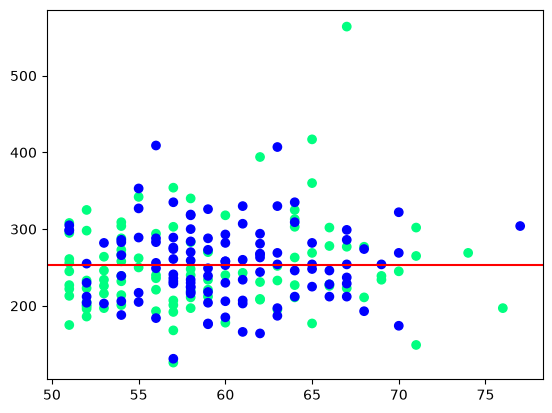

In [ ]:
fig, ax = plt.subplots()
#choose the color map named winter for your plot, convert numerical values into colors (blue and green)
ax.scatter(over_50['age'], over_50['chol'], c=over_50["target"], cmap = 'winter')

ax.axhline(over_50['chol'].mean(),  # or y = over_50['chol'].mean()
            color='r', label='Mean Cholesterol')





**Exercise 8.** Redraw the same scatter plot, but set the **axis limits** so the x-axis runs from 50 to 80 and the y-axis from 100 to 600 (use `ax.set(xlim=[50, 80], ylim=[100, 600])`).

[(50.0, 80.0), (100.0, 600.0)]

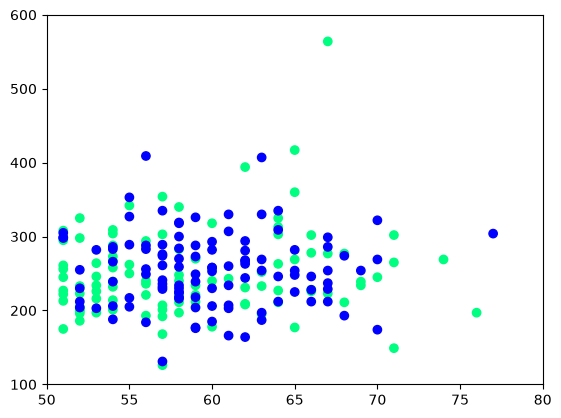

In [ ]:

fig, ax = plt.subplots()
#choose the color map named winter for your plot, convert numerical values into colors (blue and green)
ax.scatter(over_50['age'], over_50['chol'], c=over_50["target"], cmap = 'winter')

ax.set(xlim=[50, 80], ylim=[100, 600])  # numbers cover all the axis line



**Exercise 9.** Try a **built-in style**: call `plt.style.use("seaborn-v0_8")` (or `"ggplot"`), then redraw the `age` vs `chol` scatter coloured by `target`. (List options with `plt.style.available`. Reset afterwards with `plt.style.use("default")`.)

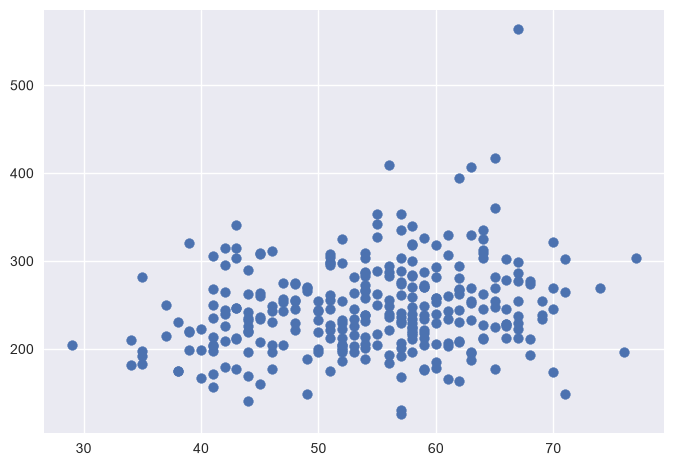

In [47]:
plt.style.use("seaborn-v0_8")  
# "ggplot"
fig, ax = plt.subplots()
ax.scatter(heart_disease['age'], heart_disease['chol'])

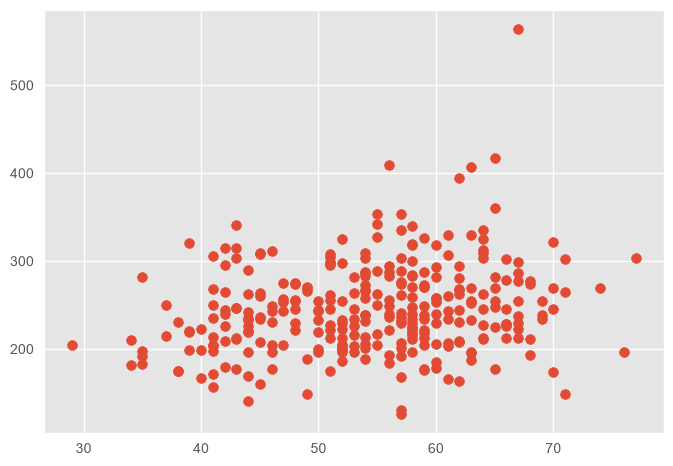

In [48]:
plt.style.use("ggplot")  
# "ggplot"
fig, ax = plt.subplots()
ax.scatter(heart_disease['age'], heart_disease['chol'])

In [49]:
plt.style.available

['Solarize_Light2',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'petroff6',
 'petroff8',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

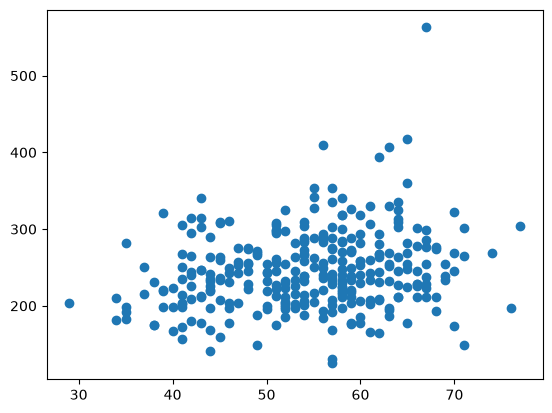

In [50]:
plt.style.use("default")  
fig, ax = plt.subplots()
ax.scatter(heart_disease['age'], heart_disease['chol'])

## 5. Saving plots

**Exercise 10.** Build any plot you like from the data, then **save the figure** to `heart-disease-analysis.png` using `fig.savefig(fname=..., dpi=100)`.

Text(0.5, 1.0, 'Age and Cholesterol Level')

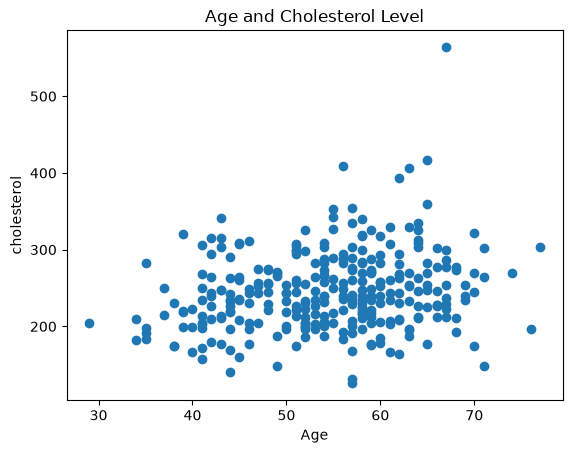

In [53]:
fig, ax = plt.subplots()
ax.scatter(heart_disease['age'], heart_disease['chol'])
ax.set_xlabel('Age')
ax.set_ylabel('cholesterol')
ax.set_title('Age and Cholesterol Level')

In [56]:
fig.savefig(fname= 'heart-disease-analysis.png', dpi=100)

## 🏆 Challenge Exercises

1. Build the **2-row shared-x dashboard** (`age` vs `chol` on top, `age` vs `thalach` below) but use `cmap="winter"` on both, add a **mean line** to each, and set `xlim=[50, 80]`.
2. Add a shared figure title to the dashboard with `fig.suptitle("Heart Disease Analysis (patients over 50)")`.
3. Save the finished dashboard to `heart-disease-analysis.png` with `dpi=100` and `bbox_inches="tight"`.

Text(0.5, 0.98, 'Heart Disease Analysis (patients over 50)')

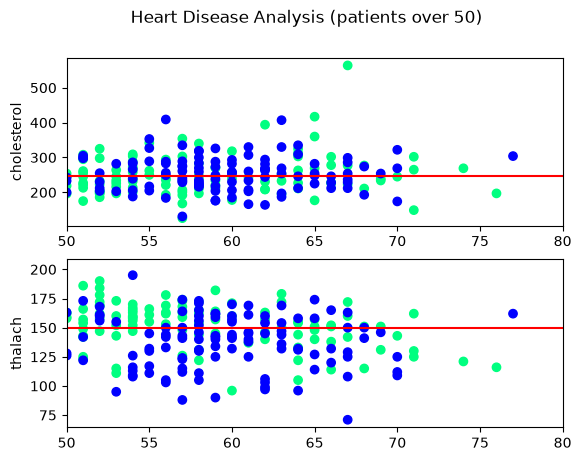

In [75]:
#1 
fig, (ax1, ax2) = plt.subplots(nrows =2, ncols = 1)
ax1.scatter(heart_disease['age'], heart_disease['chol'],  c=heart_disease['target'], cmap = 'winter')
ax1.set(xlim = [50, 80])
ax1.set_ylabel('cholesterol')
ax1.axhline(y=heart_disease['chol'].mean(), color = 'r')


ax2.scatter(heart_disease['age'], heart_disease['thalach'], c=heart_disease['target'], cmap = 'winter')
ax2.set(xlim = [50, 80])
ax2.set_ylabel('thalach')
ax2.axhline(y=heart_disease['thalach'].mean(), color = 'r')

#2
fig.suptitle("Heart Disease Analysis (patients over 50)")

In [77]:
fig.savefig(fname= 'heart-disease-analysis2.png', dpi=100, bbox_inches="tight")